# Лабораторная работа № 3
## DBSCAN


## Импорт библиотек


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, cut_tree
from sklearn.decomposition import PCA
from matplotlib.collections import LineCollection


## Подготовка данных


In [ ]:
# Загружаем таблицу и исключаем города с неполными данными.
DATA_URL = "https://raw.githubusercontent.com/IvanManomenov/python_data_analytics/main/lab3/Econom_Cities_data.csv"
raw3 = pd.read_csv(DATA_URL, sep=';', decimal=',', na_values=[-9999])
features3 = ['Work', 'Price', 'Salary']
cities3 = raw3.dropna(subset=features3).copy().reset_index(drop=True)
# Приводим три признака к одному масштабу.
X3 = StandardScaler().fit_transform(cities3[features3])
print('Исходно 48; исключены Cairo, Jakarta; в анализе:', len(cities3))


Исходно 48; исключены Cairo, Jakarta; в анализе: 46


## Кластеризация


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
40,0.75,4,2,9,0.8043,0.5234,"[18, 19]"
71,0.75,5,2,9,0.8043,0.5234,"[18, 19]"
72,0.80,5,2,9,0.8043,0.5234,"[18, 19]"
73,0.85,5,2,9,0.8043,0.5234,"[18, 19]"
105,0.90,6,2,9,0.8043,0.5176,"[19, 18]"
106,0.95,6,2,9,0.8043,0.5176,"[19, 18]"
9,0.75,3,2,8,0.8261,0.5120,"[19, 19]"
10,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
41,0.80,4,2,8,0.8261,0.5120,"[19, 19]"
74,0.90,5,2,8,0.8261,0.5120,"[19, 19]"


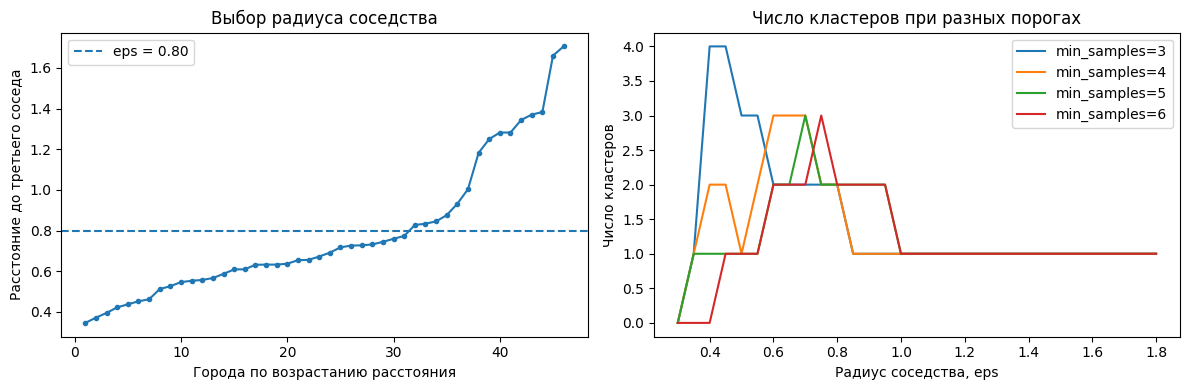

DBSCAN_RESULT: {'eps': 0.8, 'min_samples': 4, 'clusters': 2, 'noise': 8, 'coverage': np.float64(0.8260869565217391), 'silhouette_without_noise': np.float64(0.5120134885325117), 'sizes': '[19, 19]'}


,Cities,Work,Price,Salary
DBSCAN,,,,
-1,8,1900.38,99.92,61.26
1,19,1792.00,77.53,55.16
2,19,1959.21,50.12,14.79


Шум (8): Geneva, Helsinki, Hong Kong, Oslo, Stockholm, Taipei, Tokyo, Zurich
Кластер 1 (19): Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los Angeles, Luxembourg, Madrid, Milan, Montreal, New York, Paris, Sydney, Toronto, Vienna
Кластер 2 (19): Athens, Bogota, Bombay, Buenos Aires, Caracas, Johannesburg, Kuala Lumpur, Lagos, Lisbon, Manila, Mexico City, Nairobi, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Singpore, Tel Aviv


In [16]:
# Для заданных порогов считаем группы, шум и показатели качества.
def db_metrics(eps, min_samples):
    lab = DBSCAN(eps=float(eps), min_samples=int(min_samples)).fit_predict(X3)
    keep = lab != -1
    n_clusters = len(set(lab[keep]))
    score = silhouette_score(X3[keep], lab[keep]) if 2 <= n_clusters < keep.sum() else np.nan
    counts = pd.Series(lab[keep]).value_counts().sort_index().tolist()
    return {'eps':float(eps), 'min_samples':int(min_samples), 'clusters':n_clusters,
            'noise':int((~keep).sum()), 'coverage':keep.mean(),
            'silhouette_without_noise':score, 'sizes':str(counts)}

# Перебираем пороги и отбираем варианты с покрытием не ниже 80%.
db_grid = pd.DataFrame([db_metrics(ep, ms) for ms in [3,4,5,6]
                        for ep in np.round(np.arange(.30,1.81,.05),2)])
valid_db = db_grid[(db_grid.clusters>=2)&(db_grid.coverage>=.8)]
display(valid_db.sort_values(['silhouette_without_noise','coverage'], ascending=False).round(4))

# Показываем расстояния до соседей и изменение числа групп.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
neigh_dist = NearestNeighbors(n_neighbors=4).fit(X3).kneighbors(X3)[0][:,-1]
axes[0].plot(np.arange(1,len(X3)+1), np.sort(neigh_dist), 'o-', markersize=3)
axes[0].axhline(.8, linestyle='--', label='eps = 0.80')
axes[0].set(title='Выбор радиуса соседства', xlabel='Города по возрастанию расстояния', ylabel='Расстояние до третьего соседа')
axes[0].legend()
for ms in [3,4,5,6]:
    part = db_grid[db_grid.min_samples.eq(ms)]
    axes[1].plot(part.eps, part.clusters, label=f'min_samples={ms}')
axes[1].set(title='Число кластеров при разных порогах', xlabel='Радиус соседства, eps', ylabel='Число кластеров')
axes[1].legend(); plt.tight_layout(); plt.show()

# Строим итоговое разбиение при выбранных порогах.
db_eps, db_min_samples = .8, 4
db_model = DBSCAN(eps=db_eps, min_samples=db_min_samples).fit(X3)
db_raw_labels = db_model.labels_
keep3 = db_raw_labels != -1
# Нумеруем группы по убыванию средней зарплаты.
order3 = cities3.assign(temp=db_raw_labels).loc[keep3].groupby('temp').Salary.mean().sort_values(ascending=False).index
map3 = {int(old):new+1 for new,old in enumerate(order3)}
db_labels = np.array([map3[int(c)] if c!=-1 else -1 for c in db_raw_labels])
cities3['DBSCAN'] = db_labels
# Отмечаем ядровые, граничные и шумовые города.
is_core3 = np.zeros(len(X3), dtype=bool)
is_core3[db_model.core_sample_indices_] = True
cities3['Point_type'] = np.where(db_labels==-1,'noise',np.where(is_core3,'core','border'))
db_selected = db_metrics(db_eps, db_min_samples)
print('DBSCAN_RESULT:', db_selected)
# Выводим размеры, средние признаки и состав групп.
db_summary = cities3.groupby('DBSCAN').agg(
    Cities=('City','size'), Work=('Work','mean'), Price=('Price','mean'), Salary=('Salary','mean'))
display(db_summary.round(2))
for c, part in cities3.groupby('DBSCAN'):
    print(('Шум' if c==-1 else f'Кластер {c}')+f' ({len(part)}):',
          ', '.join(part.City.str.replace('_',' ').sort_values()))


### Выбранное решение

Выбираем **eps = 0,80, min_samples = 4**. При 46 наблюдениях это даёт **две группы по 19 городов и 8 шумовых точек**, то есть покрытие **82,61%**. У eps = 0,75 и того же min_samples силуэт немного выше, но к группам отнесён ещё на один город меньше. Выбор 0,80 сохраняет больше наблюдений при сопоставимом разделении; это компромисс, а не механическая максимизация силуэта.


,City,Work,Price,Salary,DBSCAN,Point_type
0,Geneva,1880.0,95.9,90.3,-1,noise
1,Helsinki,1667.0,113.6,66.6,-1,noise
2,Hong_Kong,2375.0,63.8,27.8,-1,noise
3,Oslo,1583.0,115.5,63.7,-1,noise
4,Stockholm,1805.0,111.3,39.2,-1,noise
5,Taipei,2145.0,84.3,34.5,-1,noise
6,Tokyo,1880.0,115.0,68.0,-1,noise
7,Zurich,1868.0,100.0,100.0,-1,noise
8,Amsterdam,1714.0,65.6,49.0,1,core
9,Brussels,1708.0,73.8,50.5,1,core


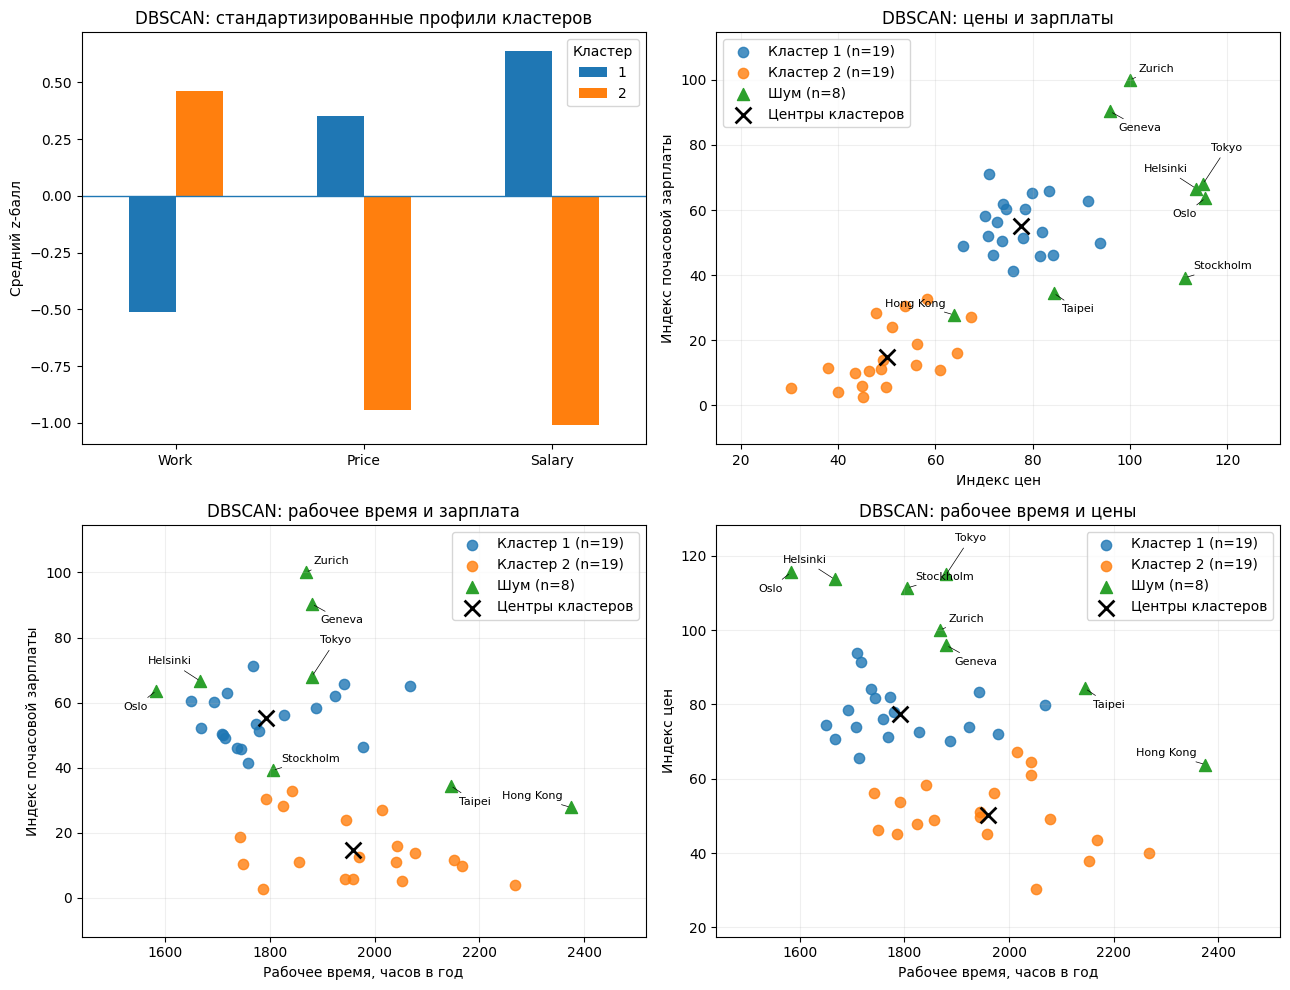

Число ядер, граничных и шумовых точек:
Point_type
core      31
noise      8
border     7


In [ ]:
# Показываем назначения и типы городов.
display(cities3.sort_values(['DBSCAN', 'City']).reset_index(drop=True))
# Отделяем шум и считаем средние точки кластеров.
clustered3 = cities3[cities3.DBSCAN != -1]
noise3 = cities3[cities3.DBSCAN == -1]
centers3 = clustered3.groupby('DBSCAN')[features3].mean()
prof3 = pd.DataFrame(X3, columns=features3).assign(DBSCAN=db_labels)
prof3 = prof3.loc[keep3].groupby('DBSCAN').mean()
# Строим профили групп и все три парные диаграммы.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()
prof3.T.plot.bar(ax=axes[0], rot=0)
axes[0].axhline(0, linewidth=1)
axes[0].set(title='DBSCAN: стандартизированные профили кластеров', ylabel='Средний z-балл')
axes[0].legend(title='Кластер')

axis_names3 = {'Work': 'Рабочее время, часов в год',
               'Price': 'Индекс цен', 'Salary': 'Индекс почасовой зарплаты'}
for ax, x, y, title in [
    (axes[1], 'Price', 'Salary', 'DBSCAN: цены и зарплаты'),
    (axes[2], 'Work', 'Salary', 'DBSCAN: рабочее время и зарплата'),
    (axes[3], 'Work', 'Price', 'DBSCAN: рабочее время и цены')
]:
    for cluster, group in clustered3.groupby('DBSCAN'):
        ax.scatter(group[x], group[y], s=55, alpha=.8,
                   label=f'Кластер {cluster} (n={len(group)})')
    # Отмечаем шумовые города.
    ax.scatter(noise3[x], noise3[y], marker='^', s=75,
               label=f'Шум (n={len(noise3)})')
    # Подписываем все шумовые города.
    offsets = [(6, -14), (-6, 12), (-6, 6), (-6, -14),
               (6, 6), (6, -14), (6, 24), (6, 6)]
    for i, (_, city) in enumerate(noise3.iterrows()):
        dx, dy = offsets[i % len(offsets)]
        ax.annotate(city.City.replace('_', ' '), (city[x], city[y]),
                    xytext=(dx, dy), textcoords='offset points', fontsize=8,
                    ha='left' if dx > 0 else 'right',
                    arrowprops={'arrowstyle': '-', 'linewidth': .5})
    ax.margins(x=.18, y=.15)
    # Добавляем средние точки кластеров.
    ax.scatter(centers3[x], centers3[y], marker='x', c='black',
               s=130, linewidths=2, zorder=5, label='Центры кластеров')
    ax.set(title=title, xlabel=axis_names3[x], ylabel=axis_names3[y])
    ax.legend()
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
print('Число ядер, граничных и шумовых точек:')
print(cities3.Point_type.value_counts().to_string())


### Интерпретация групп и шума

| Группа | n | Work, среднее | Price, среднее | Salary, среднее | Интерпретация |
|---|---:|---:|---:|---:|---|
| 1 | 19 | 1792,00 | 77,53 | 55,16 | Плотная группа с более высокими ценами и зарплатами и меньшим рабочим временем |
| 2 | 19 | 1959,21 | 50,12 | 14,79 | Плотная группа с более низкими ценами и зарплатами и большим рабочим временем |

В первую группу входят, например, Amsterdam, London и New York; во вторую — Athens, Bombay и Mexico City. Обе группы сохраняют основной экономический контраст из предыдущих работ.

**Шум:** Geneva, Helsinki, Hong Kong, Oslo, Stockholm, Taipei, Tokyo и Zurich. Это 8 городов, не присоединённых к плотным группам при выбранных параметрах. Они неоднородны: Geneva, Helsinki, Oslo, Stockholm, Tokyo и Zurich имеют высокие индексы цен; Hong Kong отличается большим рабочим временем, а Taipei также сочетанием рабочего времени и цен. Отсутствие собственной достаточно плотной группы нельзя трактовать как общую экономическую характеристику всех восьми городов. Средние по шуму приведены только описательно.

### Чувствительность и сравнение методов


### Почему DBSCAN объединяет эти города?

Закрашенные кружки — ядра, пустые — граничные точки, треугольники — шум. Линии показывают близость в исходном пространстве трёх стандартизированных признаков. На плоскости PCA расстояния могут искажаться: близость на рисунке сама по себе не означает наличие связи. Чёрные крестики — средние точки групп, которые не участвуют в работе DBSCAN.


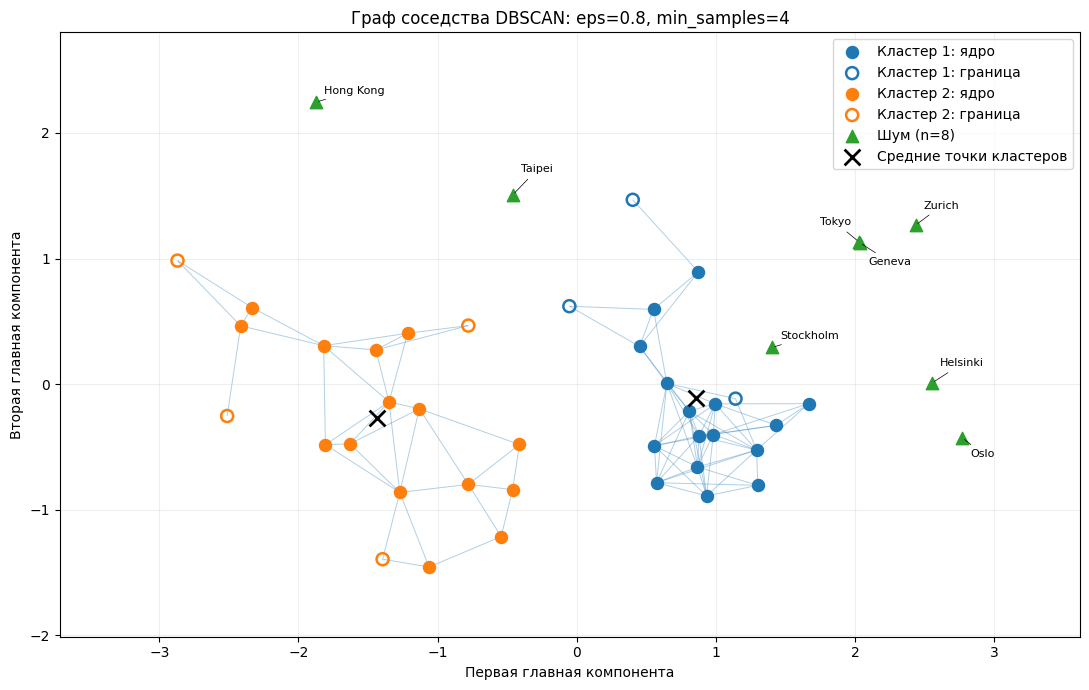

Две компоненты сохраняют 93.5% разброса. Связей на графе: 96.


In [ ]:
# Получаем координаты городов для двумерного рисунка.
graph_pca = PCA(n_components=2)
graph_xy = graph_pca.fit_transform(X3)
# Считаем расстояния между городами по трём признакам.
graph_distances = np.linalg.norm(X3[:, None, :] - X3[None, :, :], axis=2)
# Собираем связи между близкими городами одной группы с участием ядер.
graph_edges = []
for i in range(len(X3)):
    for j in range(i + 1, len(X3)):
        if (db_labels[i] != -1 and db_labels[i] == db_labels[j]
                and (is_core3[i] or is_core3[j]) and graph_distances[i, j] <= db_eps):
            graph_edges.append([graph_xy[i], graph_xy[j]])
# Рисуем связи, ядра и граничные города.
fig, ax = plt.subplots(figsize=(11, 7))
ax.add_collection(LineCollection(graph_edges, linewidths=.7, alpha=.35, zorder=1))
for cluster in sorted(set(db_labels) - {-1}):
    core_mask = (db_labels == cluster) & is_core3
    border_mask = (db_labels == cluster) & ~is_core3
    points = ax.scatter(graph_xy[core_mask, 0], graph_xy[core_mask, 1], s=75,
                        label=f'Кластер {cluster}: ядро', zorder=3)
    ax.scatter(graph_xy[border_mask, 0], graph_xy[border_mask, 1], s=75,
               facecolors='none', edgecolors=points.get_facecolor()[0], linewidths=1.8,
               label=f'Кластер {cluster}: граница', zorder=3)
# Добавляем шумовые города и их названия.
noise_indices = np.flatnonzero(db_labels == -1)
ax.scatter(graph_xy[noise_indices, 0], graph_xy[noise_indices, 1], marker='^', s=80,
           label=f'Шум (n={len(noise_indices)})', zorder=3)
noise_offsets = [(6, -16), (6, 12), (6, 6), (6, -14),
                 (6, 6), (6, 16), (-6, 12), (6, 12)]
for number, i in enumerate(noise_indices):
    dx, dy = noise_offsets[number % len(noise_offsets)]
    ax.annotate(cities3.loc[i, 'City'].replace('_', ' '), graph_xy[i],
                xytext=(dx, dy), textcoords='offset points', fontsize=8,
                ha='left' if dx > 0 else 'right',
                arrowprops={'arrowstyle': '-', 'linewidth': .5})
# Отмечаем средние точки кластеров и оформляем график.
mean_points = np.array([X3[db_labels == cluster].mean(axis=0)
                        for cluster in sorted(set(db_labels) - {-1})])
mean_xy = graph_pca.transform(mean_points)
ax.scatter(mean_xy[:, 0], mean_xy[:, 1], marker='x', c='black',
           s=130, linewidths=2, label='Средние точки кластеров', zorder=4)
explained = graph_pca.explained_variance_ratio_.sum() * 100
ax.set(title=f'Граф соседства DBSCAN: eps={db_eps}, min_samples={db_min_samples}',
       xlabel='Первая главная компонента', ylabel='Вторая главная компонента')
ax.margins(.15)
ax.legend()
ax.grid(alpha=.2)
plt.tight_layout()
plt.show()
print(f'Две компоненты сохраняют {explained:.1f}% разброса. Связей на графе: {len(graph_edges)}.')


Внутри двух групп есть цепочки связей через ядра. Граничные города присоединяются к ним, а восемь шумовых не имеют связей с ядрами при выбранном радиусе. Две компоненты PCA сохраняют 93,5% разброса, но связи на графе определяются исходными тремя признаками.


In [ ]:
# Сравниваем число групп и шумовых городов при соседних порогах.
nearby3 = db_grid[db_grid.eps.between(.65,.95)]
display(nearby3.round(4))
print('Количество кластеров в окрестности параметров:')
display(nearby3.pivot(index='eps', columns='min_samples', values='clusters'))
print('Количество шумовых точек в той же окрестности:')
display(nearby3.pivot(index='eps', columns='min_samples', values='noise'))

# Получаем разбиения из первых двух лабораторных.
km3 = KMeans(n_clusters=2, n_init=50, random_state=42).fit_predict(X3)
ward3 = cut_tree(linkage(X3, method='ward'), n_clusters=2).ravel()
# Сравниваем методы на полной выборке и на общих нешумовых городах.
comparison3 = []
for name, lab in [('Ward',ward3),('K-means',km3),('DBSCAN',db_labels)]:
    full_sil = silhouette_score(X3,lab) if name!='DBSCAN' else np.nan
    common_sil = silhouette_score(X3[keep3],lab[keep3])
    comparison3.append({'Method':name,'Clusters':len(set(lab)-{-1}),
                        'Noise':int((lab==-1).sum()), 'Coverage':float((lab!=-1).mean()),
                        'Silhouette_all_46':full_sil,'Silhouette_common_38':common_sil,
                        'ARI_vs_DBSCAN_common':adjusted_rand_score(db_labels[keep3],lab[keep3])})
comparison3 = pd.DataFrame(comparison3)
display(comparison3.round(4))
# Сохраняем назначения, профили, сетку порогов и сравнение методов.
cities3.to_csv('lab3_dbscan_clusters.csv', index=False, encoding='utf-8-sig')
db_summary.to_csv('lab3_dbscan_profiles.csv', encoding='utf-8-sig')
db_grid.to_csv('lab3_dbscan_parameter_grid.csv', index=False, encoding='utf-8-sig')
comparison3.to_csv('labs_1_3_comparison.csv', index=False, encoding='utf-8-sig')


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
7,0.65,3,2,13,0.7174,0.5454,"[16, 17]"
8,0.70,3,2,11,0.7609,0.5400,"[17, 18]"
9,0.75,3,2,8,0.8261,0.5120,"[19, 19]"
10,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
11,0.85,3,1,8,0.8261,NaN,[38]
12,0.90,3,1,8,0.8261,NaN,[38]
13,0.95,3,1,8,0.8261,NaN,[38]
38,0.65,4,3,15,0.6739,0.3793,"[16, 4, 11]"
39,0.70,4,3,11,0.7609,0.3565,"[17, 4, 14]"
40,0.75,4,2,9,0.8043,0.5234,"[18, 19]"


Количество кластеров в окрестности параметров:


min_samples,3,4,5,6
eps,,,,
0.65,2,3,2,2
0.70,2,3,3,2
0.75,2,2,2,3
0.80,2,2,2,2
0.85,1,1,2,2
0.90,1,1,2,2
0.95,1,1,2,2


Количество шумовых точек в той же окрестности:


min_samples,3,4,5,6
eps,,,,
0.65,13,15,25,27
0.70,11,11,21,24
0.75,8,9,9,16
0.80,8,8,9,12
0.85,8,8,9,11
0.90,8,8,8,9
0.95,8,8,8,9


,Method,Clusters,Noise,Coverage,Silhouette_all_46,Silhouette_common_38,ARI_vs_DBSCAN_common
0,Ward,2,0,1.0000,0.4705,0.512,1.0
1,K-means,2,0,1.0000,0.4705,0.512,1.0
2,DBSCAN,2,8,0.8261,NaN,0.512,1.0


### Вывод по DBSCAN и сравнение трёх работ

При **eps = 0,80, min_samples = 4** DBSCAN выделил **2 кластера по 19 городов** и **8 шумовых наблюдений**. Силуэт без шума — **0,5120**, покрытие — **82,61%**. Группы интерпретируются как два различных сочетания цен, почасовых зарплат и рабочего времени. Шумовые города перечислены и разобраны отдельно.

**Чувствительность существенна:** при min_samples = 4 и eps = 0,75 ещё сохраняются две группы (9 шумовых точек), но при eps = 0,85 группы уже сливаются в одну (8 шумовых точек). Следовательно, результат не следует представлять как единственное устойчивое число естественных групп; он зависит от принятого масштаба плотности.

| Метод | Группы | Шум | Покрытие 46 городов | Силуэт на всех 46 | Силуэт на общих 38 |
|---|---:|---:|---:|---:|---:|
| Ward | 2: 25 и 21 | 0 | 100% | 0,4705 | 0,5120 |
| k-means | 2: 25 и 21 | 0 | 100% | 0,4705 | 0,5120 |
| DBSCAN | 2: 19 и 19 | 8 | 82,61% | не рассчитывается | 0,5120 |

На общей подвыборке 38 городов **все три разбиения совпадают (ARI = 1)**. Более высокий силуэт DBSCAN по сравнению с 0,4705 объясняется в данном сравнении выбором подмножества объектов, поэтому не доказывает превосходство DBSCAN. Для общей сегментации всех полных наблюдений Ward и k-means удобнее; DBSCAN дополнительно показывает города, не включённые в плотные группы при выбранных параметрах.


## Что если выбрать другие пороги

Изменим eps и min_samples. Проверим, улучшается ли разделение и сколько городов при этом остаётся вне кластеров.


Исходный вариант: eps=0.80, min_samples=4. Силуэт считается без шума.


,eps,min_samples,clusters,noise,coverage,silhouette_without_noise,sizes
0,0.80,4,2,8,0.8261,0.5120,"[19, 19]"
1,0.65,4,3,15,0.6739,0.3793,"[16, 4, 11]"
2,0.75,4,2,9,0.8043,0.5234,"[18, 19]"
3,0.85,4,1,8,0.8261,NaN,[38]
4,0.80,3,2,8,0.8261,0.5120,"[19, 19]"
5,0.80,5,2,9,0.8043,0.5234,"[18, 19]"
6,0.80,6,2,12,0.7391,0.5393,"[18, 16]"
7,0.65,6,2,27,0.4130,0.7216,"[13, 6]"
8,0.95,5,2,8,0.8261,0.5120,"[19, 19]"


Сравнение на одних и тех же городах:


,eps,min_samples,Общих городов,Силуэт исходного на общих,Силуэт нового на общих,ARI на общих
0,0.80,4,38,0.5120,0.5120,1.0000
1,0.65,4,31,0.5542,0.3793,0.8094
2,0.75,4,37,0.5234,0.5234,1.0000
3,0.85,4,38,0.5120,NaN,0.0000
4,0.80,3,38,0.5120,0.5120,1.0000
5,0.80,5,37,0.5234,0.5234,1.0000
6,0.80,6,34,0.5393,0.5393,1.0000
7,0.65,6,19,0.7216,0.7216,1.0000
8,0.95,5,38,0.5120,0.5120,1.0000


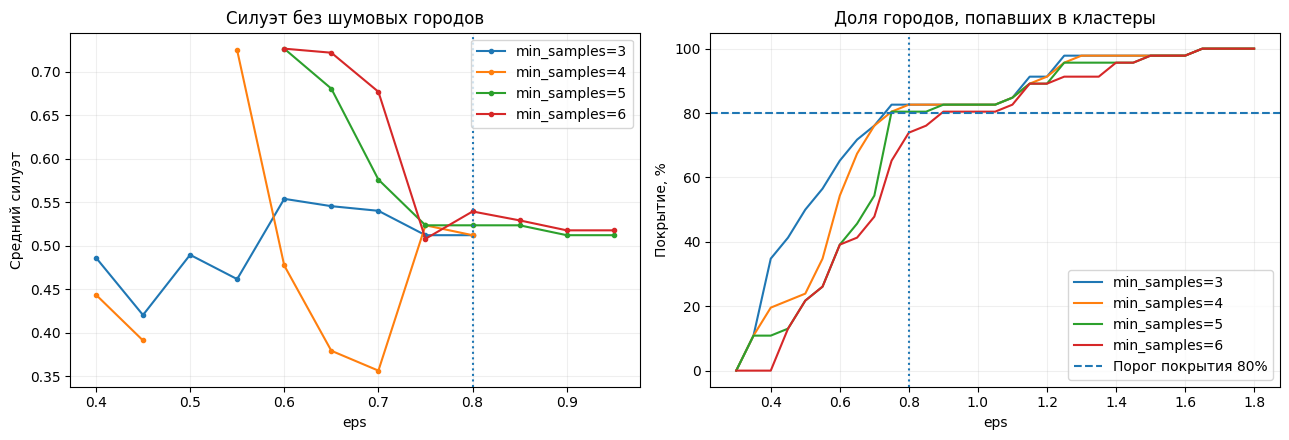

eps=0.75, min_samples=4: дополнительно стали шумом — Los Angeles
eps=0.80, min_samples=6: дополнительно стали шумом — Bombay, Los Angeles, Manila, Tel Aviv
eps=0.65, min_samples=6: дополнительно стали шумом — Athens, Bogota, Bombay, Chicago, Houston, Kuala Lumpur, Lagos, Lisbon, Los Angeles, Luxembourg, Manila, New York, Nicosia, Panama, Rio de Janeiro, San Paulo, Seoul, Tel Aviv, Toronto


In [ ]:
# Проверяем альтернативные сочетания порогов.
threshold_cases = [(.80, 4), (.65, 4), (.75, 4), (.85, 4),
                   (.80, 3), (.80, 5), (.80, 6), (.65, 6), (.95, 5)]
threshold_rows, common_rows = [], []
for eps, min_samples in threshold_cases:
    alternative = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X3)
    threshold_rows.append(db_metrics(eps, min_samples))
    # Сравниваем разбиения на городах, вошедших в группы в обоих вариантах.
    common_mask = (db_labels != -1) & (alternative != -1)
    base_common = db_labels[common_mask]
    alternative_common = alternative[common_mask]
    n_common = int(common_mask.sum())
    base_ok = 2 <= len(set(base_common)) < n_common
    alternative_ok = 2 <= len(set(alternative_common)) < n_common
    common_rows.append({
        'eps': eps, 'min_samples': min_samples, 'Общих городов': n_common,
        'Силуэт исходного на общих': silhouette_score(X3[common_mask], base_common) if base_ok else np.nan,
        'Силуэт нового на общих': silhouette_score(X3[common_mask], alternative_common) if alternative_ok else np.nan,
        'ARI на общих': adjusted_rand_score(base_common, alternative_common) if n_common else np.nan})

# Выводим показатели альтернативных разбиений.
threshold_results = pd.DataFrame(threshold_rows)
threshold_common = pd.DataFrame(common_rows)
print('Исходный вариант: eps=0.80, min_samples=4. Силуэт считается без шума.')
display(threshold_results.round(4))
print('Сравнение на одних и тех же городах:')
display(threshold_common.round(4))

# Сравниваем изменение силуэта и покрытия при смене порогов.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for min_samples in [3, 4, 5, 6]:
    part = db_grid[db_grid.min_samples.eq(min_samples)]
    axes[0].plot(part.eps, part.silhouette_without_noise, marker='o', markersize=3,
                 label=f'min_samples={min_samples}')
    axes[1].plot(part.eps, part.coverage * 100, label=f'min_samples={min_samples}')
axes[0].set(title='Силуэт без шумовых городов', xlabel='eps', ylabel='Средний силуэт')
axes[1].set(title='Доля городов, попавших в кластеры', xlabel='eps', ylabel='Покрытие, %')
axes[1].axhline(80, linestyle='--', label='Порог покрытия 80%')
for ax in axes:
    ax.axvline(db_eps, linestyle=':')
    ax.legend()
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

# Перечисляем города, дополнительно ставшие шумом.
for eps, min_samples in [(.75, 4), (.80, 6), (.65, 6)]:
    alternative = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X3)
    new_noise = cities3.loc[(alternative == -1) & (db_labels != -1), 'City']
    print(f'eps={eps:.2f}, min_samples={min_samples}: дополнительно стали шумом —',
          ', '.join(new_noise.str.replace('_', ' ')))
# Сохраняем результаты экспериментов с порогами.
threshold_results.to_csv('lab3_alternative_thresholds.csv', index=False, encoding='utf-8-sig')
threshold_common.to_csv('lab3_alternative_thresholds_common.csv', index=False, encoding='utf-8-sig')


### Стало ли лучше?

| eps | min_samples | Кластеров | Шумовых городов | Силуэт без шума |
|---:|---:|---:|---:|---:|
| 0,80 | 4 | 2 | 8 | 0,5120 |
| 0,75 | 4 | 2 | 9 | 0,5234 |
| 0,80 | 6 | 2 | 12 | 0,5393 |
| 0,65 | 6 | 2 | 27 | 0,7216 |
| 0,85 | 4 | 1 | 8 | не рассчитывается |

**Если немного уменьшить eps до 0,75**, силуэт чуть растёт, но Лос-Анджелес дополнительно становится шумом. При eps=0,80 и min_samples=5 получается то же разбиение на 37 городах.

**Если повысить min_samples до 6 при eps=0,80**, шумовых городов становится 12. Если одновременно уменьшить eps до 0,65, силуэт растёт до 0,7216, но в группах остаётся всего 19 из 46 городов — около 41%. Большая часть данных исключена из кластеров.

На общих городах во всех этих вариантах разбиения совпадают с исходным (ARI=1), и силуэты при расчёте на одной и той же подвыборке тоже совпадают. Рост метрики здесь объясняется отбором более компактного подмножества, а не лучшим разделением тех же городов.

**Если увеличить eps до 0,85 при min_samples=4**, две группы соединяются в одну. Если уменьшить eps до 0,65 при min_samples=4, появляются три группы, но шумовых городов уже 15, а силуэт падает до 0,3793.

**При eps=0,80, min_samples=3 и при eps=0,95, min_samples=5** получаем тот же результат, что и в исходном варианте: две группы по 19 городов и 8 шумовых.

**Явного улучшения для задачи выделения нескольких групп с покрытием хотя бы 80% не получилось.** Исходные пороги 0,80 и 4 остаются разумным компромиссом. Вариант 0,75 и 4 тоже допустим, если важнее немного более высокий силуэт и можно оставить ещё один город вне групп. Сам по себе больший силуэт без учёта количества шума не означает лучший результат.
